# 實驗一：Evo2 計分窗口大小對致病性判別準確率的影響

**問的問題**：`config.EVO2_WINDOW_SIZE` 現在是 8,192 bp。窗口取多大，會不會改變
Evo2 zero-shot 區分 ClinVar pathogenic / benign 的能力？

**方法**：對每顆變異、每個窗口大小 W ∈ {1024, 2048, 4096, 8192}，取出以變異為中心
的 ref / var 兩條序列，各做一次 forward pass，用 `log_softmax` + `gather` 取出
**逐位置** 的 log-likelihood（就是 `evo2.scoring.logits_to_logprobs` 的做法）。
delta score 定義與 `utils/evo2_predictor.py` 一致：

$$\Delta = \overline{\log p_{\text{var}}} - \overline{\log p_{\text{ref}}}$$

平均取在整個窗口上（`score_sequences(reduce_method='mean')` 就是這樣算的）。
因為逐位置的 logprob 都留著，同一次 forward 還能順便算出「只平均變異位置 ±N bp」
的版本，所以窗口大小與 focal 半徑兩件事一次量完，不必多跑 GPU。

**與論文的關係**：論文 2.2.2 節原本寫 delta score 是「±64 bp focal region 的平均」，
但程式從來沒有這個 focal region，一直是整窗平均。這個實驗一方面量窗口大小的影響，
一方面用 focal 半徑的掃描回答「那個 ±64 的說法會不會改變結論」。論文的敘述已依實作
更正（見本 notebook 最後一節）。

**一個結構上的事實，先講清楚**：自迴歸模型在變異位置**之前**的逐位置 logprob，ref 與
var 完全相同（前綴一樣），所以 `delta ≠ 0` 只可能出現在變異位置及其之後。窗口開得越大，
分母（窗口長度）越大而分子只多了下游位置，因此整窗平均的 delta 會隨 W 變小。AUROC 對
單調縮放不敏感，但「納入多少下游位置」會實際改變排序，這正是本實驗要量的東西。

In [ ]:
# 本 notebook 在 research/ 裡；切回 repo 根目錄，讓相對路徑與 import config / utils 照舊可用
import os, sys
from pathlib import Path
if Path.cwd().name == "research":
    os.chdir(Path.cwd().parent)
for _p in (Path.cwd(), Path.cwd() / "research"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ.setdefault("TRITON_PTXAS_PATH", "/usr/local/cuda/bin/ptxas")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

EXP_DIR = PROJECT_ROOT / "research" / "experiments"
EXP_DIR.mkdir(exist_ok=True)
EVAL_CSV = EXP_DIR / "evo2_window_eval_set.csv"      # 分層抽樣的評估集
SCORES_CSV = EXP_DIR / "evo2_window_scores.csv"      # 逐 (變異, 窗口) 的分數（可續跑）
FIG_DIR = EXP_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

WINDOWS = [1024, 2048, 4096, 8192]          # 要比較的窗口大小
FOCAL_RADII = [0, 8, 32, 64, 256, 1024]     # 附錄用：只平均變異位置 ±N bp（0 = 只看該位置）

# 圖表樣式：窗口大小是有序的量 → 單一色相由淺到深；類別用固定順序的色盤
SEQ_BLUE = {1024: "#9ec5f4", 2048: "#5598e7", 4096: "#2a78d6", 8192: "#184f95"}
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
    "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "legend.frameon": False, "font.size": 10, "lines.linewidth": 2,
    # 圖上文字一律英文（論文是英文的）；CJK 只當備援，避免偶爾出現的中文變成方框
    "font.family": ["DejaVu Sans", "Noto Sans CJK JP"],
})
print("windows:", WINDOWS)

windows: [1024, 2048, 4096, 8192]


## 1. 評估集：分層抽樣

全部 4,990 顆 × 4 個窗口要跑十幾個小時，所以抽子集。抽樣原則是「把有資訊量的都留下」：

- **全部 pathogenic**（633 顆）——正類本來就少，一顆都不能丟
- **全部 missense 與 intron 變異**——論文 3.2 節指出只有這兩類同時存在兩種標籤，
  其他類別（synonymous 全 benign、nonsense 全 pathogenic）標籤與分子後果幾乎完全共線，
  AUROC 高不代表模型懂變異
- **隨機補 benign** 到目標筆數，維持一個可比的類別比例

`N_TARGET` 調小可以先試跑；設成 `None` 就是 4,990 顆全跑。

In [2]:
N_TARGET = 1800      # 目標總筆數；None = 全部 4,990 顆
SEED = 0


def normalize_label(text: str) -> str:
    t = str(text).lower()
    if "pathogenic" in t and "benign" not in t:
        return "pathogenic"
    if "benign" in t:
        return "benign"
    return "uncertain"


def consequence_class(text: str) -> str:
    """把 ClinVar 的 molecular consequence 收斂成單一主類別（論文 3.2 節的分法）。"""
    t = str(text).lower()
    for key, name in [("nonsense", "nonsense"), ("missense", "missense"),
                      ("splice", "splice"), ("synonymous", "synonymous"),
                      ("intron", "intronic"), ("utr", "UTR")]:
        if key in t:
            return name
    return "other"


clinvar = pd.read_csv(PROJECT_ROOT / "research" / "data" / "clinvar_latest.csv", low_memory=False)
clinvar["label"] = clinvar["Germline classification"].map(normalize_label)
clinvar["consequence"] = clinvar["Molecular consequence"].map(consequence_class)
clinvar["position"] = pd.to_numeric(clinvar["position"], errors="coerce")
binary = clinvar[
    clinvar["label"].isin(["pathogenic", "benign"])
    & clinvar["position"].notna()
    & clinvar["ref"].notna() & clinvar["alt"].notna()
].copy()
binary["position"] = binary["position"].astype(int)
binary["variant_id"] = (binary["chr"].astype(str) + "-" + binary["position"].astype(str)
                        + "-" + binary["ref"].astype(str) + "-" + binary["alt"].astype(str))
binary = binary.drop_duplicates("variant_id")

if N_TARGET is None:
    eval_set = binary
else:
    rng = np.random.default_rng(SEED)
    must = binary[(binary["label"] == "pathogenic")
                  | binary["consequence"].isin(["missense", "intronic"])]
    rest = binary.drop(must.index)
    k = max(0, min(N_TARGET - len(must), len(rest)))
    extra = rest.loc[rng.choice(rest.index.to_numpy(), size=k, replace=False)] if k else rest.iloc[:0]
    eval_set = pd.concat([must, extra])

eval_set = eval_set[["variant_id", "chr", "position", "ref", "alt", "label",
                     "consequence", "Name", "VariationID"]].reset_index(drop=True)
eval_set.to_csv(EVAL_CSV, index=False)

print(f"評估集 {len(eval_set)} 顆 -> {EVAL_CSV}")
print(eval_set["label"].value_counts().to_string())
print(pd.crosstab(eval_set["consequence"], eval_set["label"]).to_string())

評估集 1800 顆 -> /home/ryan910702/ttn-agent/experiments/evo2_window_eval_set.csv
label
benign        1167
pathogenic     633
label        benign  pathogenic
consequence                    
intronic        570           1
missense        361           9
nonsense          0         540
splice            0          83
synonymous      236           0


## 2. 載入 Evo2（只載一次）

`Evo2Predictor` 負責 TTN 參考序列的座標換算（負鏈、已反向互補的 FASTA），這裡沿用它，
只把 `window_size` 換掉，確保與正式流程取窗的方式完全一致。

**GPU 是獨佔的**：如果 `run_batch_inprocess.sh` 還在跑（vLLM 佔了 85% 的記憶體），
這一格會 OOM。先確認批次已結束。

In [3]:
import torch
from evo2.scoring import logits_to_logprobs, prepare_batch

from utils.evo2_predictor import Evo2Predictor

predictor = Evo2Predictor()
predictor._load_model()
predictor._load_reference_sequence()

evo2_model = predictor.model.model          # StripedHyena 本體
tokenizer = predictor.model.tokenizer
print("TTN 參考序列:", len(predictor.seq_ttn), "bp")

[09/20/26 22:29:44] INFO     utils.evo2_predictor - INFO - Loading Evo2 model: evo2_7b_base    ]8;id=216877;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=216878;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#39\39]8;;\

                    INFO     httpx - INFO - HTTP Request: GET                                       ]8;id=216885;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=216886;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/httpx/_client.py#1025\1025]8;;\
                             https://huggingface.co/api/models/arcinstitute/evo2_7b_base/revision/m                
                             ain "HTTP/1.1 200 OK"                                                                 

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 105517.08it/s]

Found complete file in repo: evo2_7b_base.pt


                    INFO     StripedHyena - INFO - Initializing StripedHyena with config:              ]8;id=216893;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/vortex/model/model.py\model.py]8;;\:]8;id=216894;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/vortex/model/model.py#627\627]8;;\
                             {'model_name': 'shc-evo2-7b-8k-2T-v2', 'vocab_size': 512, 'hidden_size':              
                             4096, 'num_filters': 4096, 'hcl_layer_idxs': [2, 6, 9, 13, 16, 20, 23,                
                             27, 30], 'hcm_layer_idxs': [1, 5, 8, 12, 15, 19, 22, 26, 29],                         
                             'hcs_layer_idxs': [0, 4, 7, 11, 14, 18, 21, 25, 28], 'attn_layer_idxs':               
                             [3, 10, 17, 24, 31], 'hcm_filter_length': 128, 'hcl_filter_groups': 4096,             
                             'hcm_filter_groups': 256, 'hcs_filter_groups': 256, 'hcs_filter_length':              
                             7, 'num_layers': 32, 'short_filter_length': 3, 'num_attention_heads': 32,             
                             'short_filter_bias': False, 'mlp_init_method': 'torch.nn.init.zeros_',                
                             'mlp_output_init_method': 'torch.nn.init.zeros_', 'eps': 1e-06,                       
                             'state_size': 16, 'rotary_emb_base': 10000,                                           
                             'make_vocab_size_divisible_by': 8, 'inner_size_multiple_of': 16,                      
                             'inner_mlp_size': 11008, 'log_intermediate_values': False, 'proj_groups':             
                             1, 'hyena_filter_groups': 1, 'column_split_hyena': False, 'column_split':             
                             True, 'interleave': True, 'evo2_style_activations': True,                             
                             'model_parallel_size': 1, 'pipe_parallel_size': 1, 'tie_embeddings':                  
                             True, 'mha_out_proj_bias': True, 'hyena_out_proj_bias': True,                         
                             'hyena_flip_x1x2': False, 'qkv_proj_bias': False,                                     
                             'use_fp8_input_projections': False, 'max_seqlen': 32768,                              
                             'max_batch_size': 1, 'final_norm': True, 'use_flash_attn': True,                      
                             'use_flash_rmsnorm': False, 'use_flash_depthwise': False, 'use_flashfft':             
                             False, 'use_laughing_hyena': False, 'inference_mode': True,                           
                             'tokenizer_type': 'CharLevelTokenizer', 'prefill_style': 'fft',                       
                             'mlp_activation': 'gelu', 'print_activations': False, 'Loader': <class                
                             'yaml.loader.FullLoader'>}                                                            

                    INFO     StripedHyena - INFO - Initializing 32 blocks...                           ]8;id=216900;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/vortex/model/model.py\model.py]8;;\:]8;id=216901;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/vortex/model/model.py#646\646]8;;\

... (78 outputs left out)

                    INFO     utils.evo2_predictor - INFO - Evo2 model loaded successfully      ]8;id=217322;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217323;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#41\41]8;;\

                    INFO     utils.evo2_predictor - INFO - Loading TTN reference sequence...   ]8;id=217329;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217330;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#56\56]8;;\

                    INFO     utils.evo2_predictor - INFO - TTN reference sequence loaded:      ]8;id=217336;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217337;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#61\61]8;;\
                             281435 bp (chr2:178807423-178525989)                                                  

TTN 參考序列: 281435 bp


## 3. 計分：一次 forward、多種 reduce

`_parse_sequences` 會依 `predictor.window_size` 取出以變異為中心的窗口，並驗證 ref base
對得上；回傳的 ref / var 兩條序列長度相同，可以放進同一個 batch。

`logits_to_logprobs` 回傳的陣列長度是 L-1，索引 k 對應序列位置 k+1（前一個 token 預測
下一個）。所以變異位置 p（0-based）對應的索引是 p-1，focal 半徑 N 就是索引區間
[p-N-1, p+N-1]。

In [4]:
def windows_for(variant, window_size):
    """取出 (ref_seq, var_seq, 變異在窗口內的 0-based 索引)。"""
    predictor.window_size = window_size
    ref_seq, var_seq = predictor._parse_sequences(
        int(variant["position"]), str(variant["ref"]), str(variant["alt"])
    )
    if ref_seq is None:
        return None, None, None
    seq_index = predictor.ttn_start - int(variant["position"])
    start = max(0, seq_index - window_size // 2)
    return ref_seq, var_seq, seq_index - start


def score_pair(ref_seq, var_seq, snv_idx):
    """回傳各種 reduce 方式下的 delta score。"""
    input_ids, seq_lengths = prepare_batch([ref_seq, var_seq], tokenizer, device="cuda:0")
    with torch.inference_mode():
        logits, _ = evo2_model(input_ids)
    logprobs = logits_to_logprobs(logits, input_ids).float().cpu().numpy()
    lp_ref, lp_var = logprobs[0][: seq_lengths[0]], logprobs[1][: seq_lengths[1]]
    delta = lp_var - lp_ref                      # 索引 k ↔ 序列位置 k+1

    out = {
        "ref_score": float(lp_ref.mean()),
        "var_score": float(lp_var.mean()),
        "delta_mean_window": float(delta.mean()),        # 與 evo2_predictor.py 相同
        "delta_sum_window": float(delta.sum()),
        "n_positions": int(delta.size),
        "n_changed": int(np.count_nonzero(delta)),
    }
    for radius in FOCAL_RADII:
        lo = max(0, snv_idx - radius - 1)
        hi = min(delta.size, snv_idx + radius)       # 右開
        seg = delta[lo:hi] if hi > lo else delta[max(0, snv_idx - 1): snv_idx]
        out[f"delta_focal_{radius}"] = float(seg.mean()) if seg.size else np.nan
    return out


# 先量一顆的耗時，估整批時間
probe = eval_set.iloc[0]
for w in WINDOWS:
    r, v, i = windows_for(probe, w)
    t0 = time.time()
    s = score_pair(r, v, i)
    print(f"W={w:>5}: {time.time() - t0:5.2f}s  delta_mean={s['delta_mean_window']:+.3e} "
          f"changed={s['n_changed']}/{s['n_positions']}")

                    INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217343;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217344;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178527121 -> seq index 280302, window size 1024 bp                                

W= 1024:  1.50s  delta_mean=-4.039e-02 changed=811/1023


[09/20/26 22:31:28] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217349;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217350;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178527121 -> seq index 280302, window size 2048 bp                                

W= 2048:  1.37s  delta_mean=-1.725e-02 changed=1533/2047


[09/20/26 22:31:29] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217355;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217356;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178527121 -> seq index 280302, window size 3181 bp                                

W= 4096:  2.22s  delta_mean=-1.081e-02 changed=2445/3180


[09/20/26 22:31:31] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217361;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217362;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178527121 -> seq index 280302, window size 5229 bp                                

W= 8192:  3.84s  delta_mean=-9.218e-03 changed=3784/5228


## 4. 跑完整批（可續跑）

每算完一顆就 append 到 `experiments/evo2_window_scores.csv`，中斷後重跑這一格會自動接續。

In [6]:
CHECKPOINT_EVERY = 25

done = set()
if SCORES_CSV.exists():
    prev = pd.read_csv(SCORES_CSV)
    done = set(zip(prev["variant_id"], prev["window"]))
    print(f"續跑：已有 {len(prev)} 筆 (變異, 窗口) 結果")

rows, failures = [], []
todo = [(v, w) for _, v in eval_set.iterrows() for w in WINDOWS
        if (v["variant_id"], w) not in done]
print(f"待跑 {len(todo)} 筆")

t_start = time.time()
for n, (variant, w) in enumerate(todo, 1):
    ref_seq, var_seq, snv_idx = windows_for(variant, w)
    if ref_seq is None:
        failures.append({"variant_id": variant["variant_id"], "window": w})
        continue
    try:
        scores = score_pair(ref_seq, var_seq, snv_idx)
    except Exception as exc:
        failures.append({"variant_id": variant["variant_id"], "window": w, "error": str(exc)})
        continue
    rows.append({"variant_id": variant["variant_id"], "window": w,
                 "label": variant["label"], "consequence": variant["consequence"],
                 "window_len": len(ref_seq), **scores})

    if n % CHECKPOINT_EVERY == 0 or n == len(todo):
        pd.DataFrame(rows).to_csv(SCORES_CSV, mode="a", index=False,
                                  header=not SCORES_CSV.exists())
        rows = []
        rate = n / (time.time() - t_start)
        print(f"  {n}/{len(todo)}  {rate:.2f} 筆/秒  預計剩 "
              f"{(len(todo) - n) / max(rate, 1e-9) / 60:.1f} 分", flush=True)

print(f"完成；取窗或計分失敗 {len(failures)} 筆")
if failures:
    display(pd.DataFrame(failures).head())

續跑：已有 4775 筆 (變異, 窗口) 結果
待跑 2425 筆


[09/20/26 22:41:26] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217523;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217524;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178718126 -> seq index 89297, window size 8192 bp                                 

[09/20/26 22:41:32] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217529;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217530;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178718237 -> seq index 89186, window size 1024 bp                                 

                    INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217535;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217536;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178718237 -> seq index 89186, window size 2048 bp                                 

[09/20/26 22:41:34] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217541;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217542;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178718237 -> seq index 89186, window size 4096 bp                                 

[09/20/26 22:41:36] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=217547;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=217548;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178718237 -> seq index 89186, window size 8192 bp                                 

... (2,513 outputs left out)

[09/21/26 00:23:31] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=232055;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=232056;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178625310 -> seq index 182113, window size 2048 bp                                

[09/21/26 00:23:32] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=232061;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=232062;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178625310 -> seq index 182113, window size 4096 bp                                

[09/21/26 00:23:35] INFO     utils.evo2_predictor - INFO - Extracted sequence window: genomic ]8;id=232067;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=232068;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#146\146]8;;\
                             pos 178625310 -> seq index 182113, window size 8192 bp                                

  2425/2425  0.40 筆/秒  預計剩 0.0 分
完成；取窗或計分失敗 0 筆


## 5. 準確率 vs 窗口大小

門檻與論文一致：對 **negated delta**（越大越像 pathogenic）做 ROC，取 Youden's J 最大的
切點。AUROC 與 AUPRC 不依賴門檻，是主要指標；accuracy / precision / recall 用該窗口自己
的 Youden 門檻算，四個窗口都一樣樂觀，可以互相比。

In [7]:
scores = pd.read_csv(SCORES_CSV).drop_duplicates(["variant_id", "window"])
scores["y"] = (scores["label"] == "pathogenic").astype(int)
print(f"{scores['variant_id'].nunique()} 顆變異 × {scores['window'].nunique()} 個窗口")


def metrics_at(df, score_col="delta_mean_window"):
    """回傳一個窗口（或任一子集）的門檻無關與門檻相關指標。"""
    y, s = df["y"].to_numpy(), -df[score_col].to_numpy()   # negated delta
    if len(np.unique(y)) < 2:
        return None
    fpr, tpr, thr = roc_curve(y, s)
    j = int(np.argmax(tpr - fpr))
    pred = (s >= thr[j]).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return {
        "n": len(df), "n_pathogenic": int(y.sum()),
        "AUROC": roc_auc_score(y, s), "AUPRC": average_precision_score(y, s),
        "accuracy": (tp + tn) / len(y), "precision": prec, "recall": rec,
        "F1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
        "youden_delta_threshold": -thr[j], "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "median_delta_pathogenic": float(df.loc[df["y"] == 1, score_col].median()),
        "median_delta_benign": float(df.loc[df["y"] == 0, score_col].median()),
    }


summary = pd.DataFrame({w: metrics_at(g) for w, g in scores.groupby("window")}).T
summary.index.name = "window_bp"
display(summary.round(4))
summary.to_csv(EXP_DIR / "evo2_window_summary.csv")

1800 顆變異 × 4 個窗口


,n,n_pathogenic,AUROC,AUPRC,accuracy,precision,recall,F1,youden_delta_threshold,TP,FP,FN,TN,median_delta_pathogenic,median_delta_benign
window_bp,,,,,,,,,,,,,,,
1024,1800.0,633.0,0.9743,0.9461,0.9278,0.8608,0.9479,0.9023,-0.0068,600.0,97.0,33.0,1070.0,-0.0177,-0.0005
2048,1800.0,633.0,0.9776,0.9465,0.9294,0.8563,0.9605,0.9054,-0.0035,608.0,102.0,25.0,1065.0,-0.0091,-0.0003
4096,1800.0,633.0,0.9777,0.9484,0.9339,0.8661,0.9605,0.9109,-0.0018,608.0,94.0,25.0,1073.0,-0.0047,-0.0002
8192,1800.0,633.0,0.9776,0.9492,0.9239,0.8333,0.9795,0.9005,-0.0007,620.0,124.0,13.0,1043.0,-0.0024,-0.0001


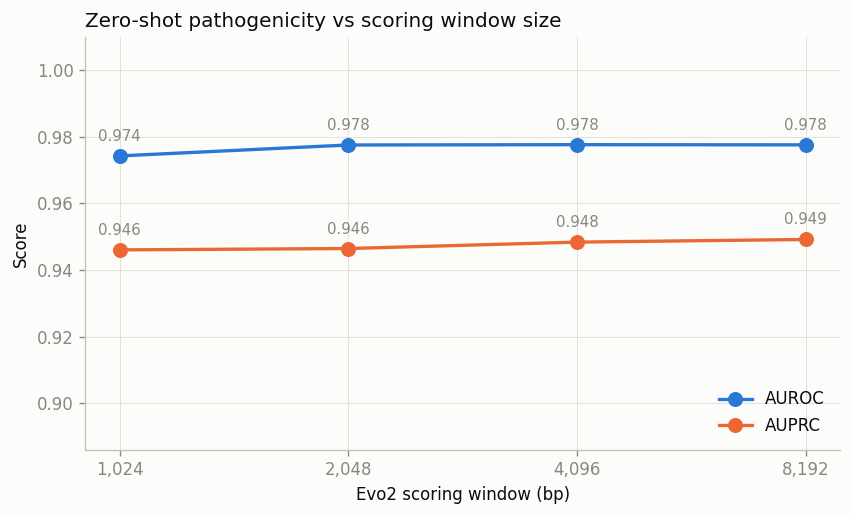

In [8]:
# AUROC / AUPRC vs 窗口大小（同一個 0-1 軸，兩條線各自直接標數值）
fig, ax = plt.subplots(figsize=(8.8, 4.4))
x = summary.index.to_numpy()
for metric, color in [("AUROC", CAT[0]), ("AUPRC", CAT[1])]:
    ax.plot(x, summary[metric], marker="o", markersize=8, color=color, label=metric)
    for xi, yi in zip(x, summary[metric]):
        ax.annotate(f"{yi:.3f}", (xi, yi), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=9, color=MUTED)
ax.set_xscale("log", base=2)
ax.set_xticks(x); ax.set_xticklabels([f"{v:,}" for v in x])
ax.set_xlabel("Evo2 scoring window (bp)")
ax.set_ylabel("Score")
ax.set_ylim(min(summary[["AUROC", "AUPRC"]].min()) - 0.06, 1.01)
ax.set_title("Zero-shot pathogenicity vs scoring window size", loc="left", fontsize=12)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.tight_layout(rect=(0, 0, 0.80, 1))
fig.savefig(FIG_DIR / "exp1_auroc_auprc_vs_window.png", bbox_inches="tight")
plt.show()

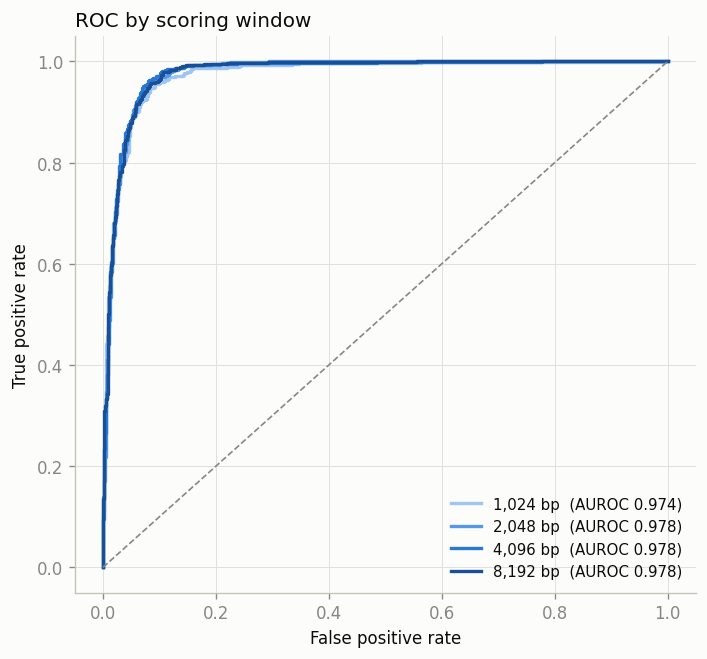

In [9]:
# ROC 曲線疊圖（窗口越大顏色越深）
fig, ax = plt.subplots(figsize=(8.2, 5.6))
for w, g in scores.groupby("window"):
    fpr, tpr, _ = roc_curve(g["y"], -g["delta_mean_window"])
    ax.plot(fpr, tpr, color=SEQ_BLUE[w], label=f"{w:,} bp  (AUROC {summary.loc[w, 'AUROC']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color=MUTED)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC by scoring window", loc="left", fontsize=12)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0, fontsize=9)
fig.tight_layout(rect=(0, 0, 0.70, 1))
fig.savefig(FIG_DIR / "exp1_roc_by_window.png", bbox_inches="tight")
plt.show()

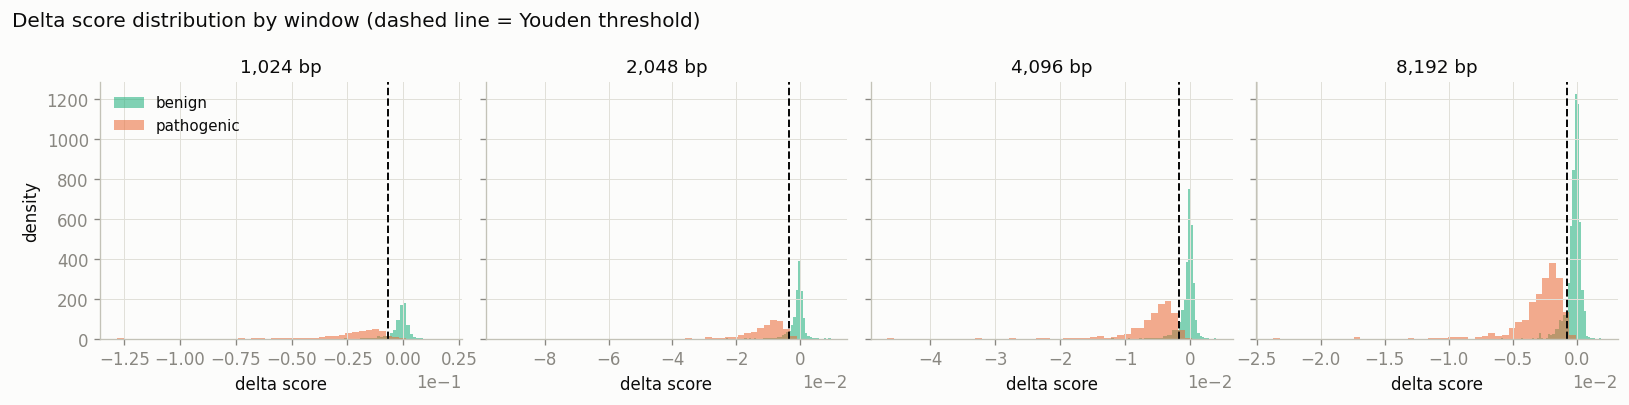

In [10]:
# delta score 的分佈：窗口越大，整窗平均被稀釋（注意每個子圖各自的 x 軸尺度）
fig, axes = plt.subplots(1, len(WINDOWS), figsize=(3.4 * len(WINDOWS), 3.4), sharey=True)
for ax, w in zip(np.atleast_1d(axes), WINDOWS):
    g = scores[scores["window"] == w]
    for label, color in [("benign", CAT[2]), ("pathogenic", CAT[1])]:
        vals = g.loc[g["label"] == label, "delta_mean_window"]
        ax.hist(vals, bins=45, color=color, alpha=0.55, label=label, density=True)
    ax.axvline(summary.loc[w, "youden_delta_threshold"], color=INK, linewidth=1.2,
               linestyle="--")
    ax.set_title(f"{w:,} bp", fontsize=11)
    ax.set_xlabel("delta score")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
np.atleast_1d(axes)[0].set_ylabel("density")
np.atleast_1d(axes)[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Delta score distribution by window (dashed line = Youden threshold)",
             x=0.005, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "exp1_delta_distribution.png", bbox_inches="tight")
plt.show()

## 6. 只看有資訊量的兩類：missense 與 intronic

其他類別的標籤與分子後果幾乎完全共線（synonymous 全 benign、nonsense 全 pathogenic），
整體 AUROC 主要在獎勵「認得出提前終止密碼子」。窗口大小的真正影響要看這兩類。

window,1024,2048,4096,8192
consequence,,,,
intronic,0.975,0.984,0.993,0.982
missense,0.781,0.824,0.831,0.786


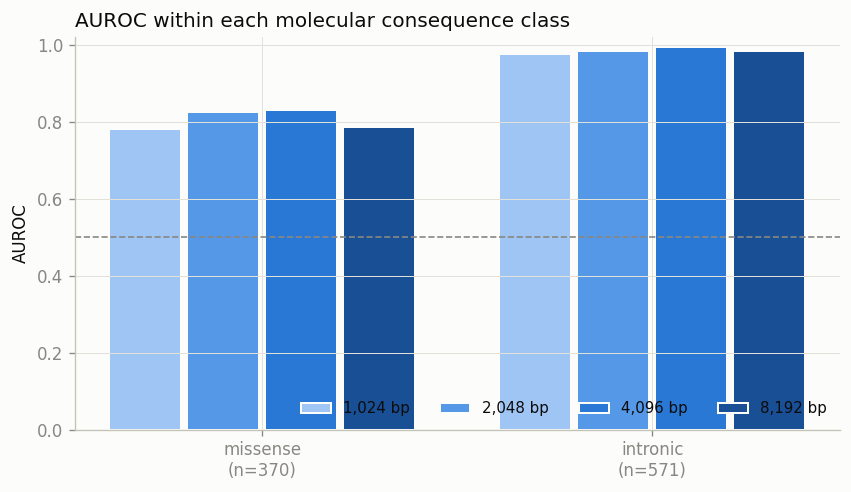

In [11]:
rows = []
for (w, cons), g in scores.groupby(["window", "consequence"]):
    m = metrics_at(g)
    if m is None or m["n"] < 30:      # 標籤單一或樣本太少 → AUROC 無意義
        continue
    rows.append({"window": w, "consequence": cons, **m})
by_cons = pd.DataFrame(rows)
display(by_cons.pivot(index="consequence", columns="window", values="AUROC").round(3))

fig, ax = plt.subplots(figsize=(9.0, 4.2))
order = [c for c in ["missense", "intronic", "synonymous", "nonsense", "splice", "other"]
         if c in set(by_cons["consequence"])]
width = 0.8 / len(WINDOWS)
for i, w in enumerate(WINDOWS):
    sub = by_cons[by_cons["window"] == w].set_index("consequence").reindex(order)
    xs = np.arange(len(order)) + (i - (len(WINDOWS) - 1) / 2) * width
    ax.bar(xs, sub["AUROC"].to_numpy(), width=width * 0.92, color=SEQ_BLUE[w],
           label=f"{w:,} bp", edgecolor="#fcfcfb", linewidth=1.2)
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle="--")
ax.set_xticks(np.arange(len(order)))
ax.set_xticklabels([f"{c}\n(n={int(by_cons[by_cons.consequence == c]['n'].iloc[0])})"
                    for c in order])
ax.set_ylabel("AUROC"); ax.set_ylim(0, 1.02)
ax.set_title("AUROC within each molecular consequence class", loc="left", fontsize=12)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0, fontsize=9)
fig.tight_layout(rect=(0, 0, 0.80, 1))
fig.savefig(FIG_DIR / "exp1_auroc_by_consequence.png", bbox_inches="tight")
plt.show()

## 7. 附錄：focal 半徑（回答論文原本寫的 ±64 bp）

同一批 forward pass 的逐位置 logprob 另外給出「只平均變異位置 ±N bp」的 delta。
`focal 0` 是只看變異那一個位置，`window` 是現行實作（整窗平均）。這張熱圖同時回答兩件事：
窗口大小重要嗎？把平均限制在變異附近有沒有幫助？

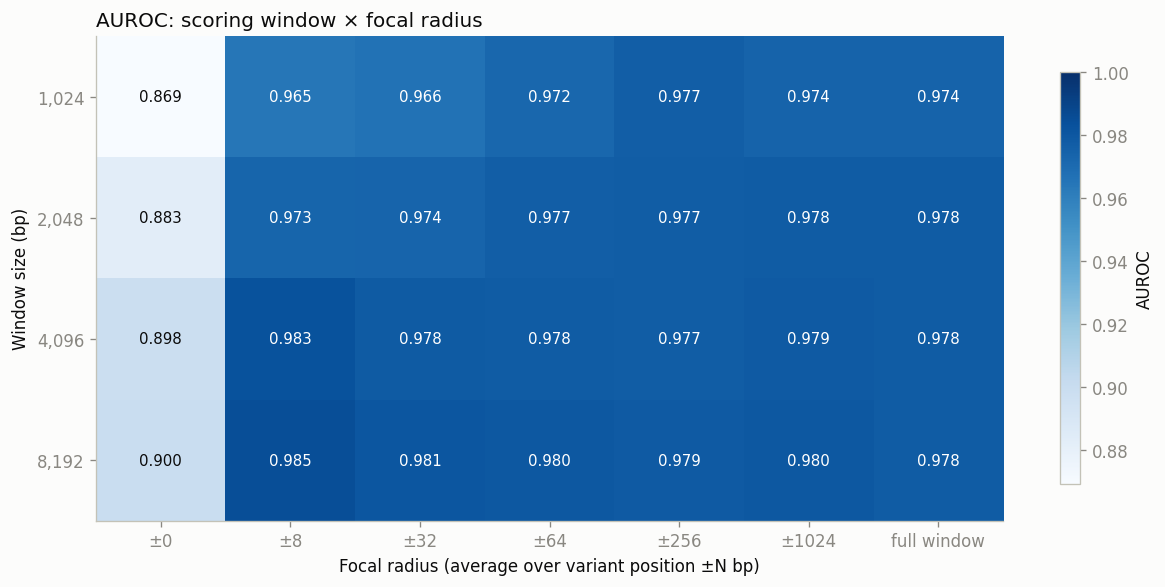

In [12]:
focal_cols = {f"delta_focal_{r}": f"±{r}" for r in FOCAL_RADII}
focal_cols["delta_mean_window"] = "full window"

heat = pd.DataFrame(index=[f"{w:,}" for w in WINDOWS], columns=list(focal_cols.values()),
                    dtype=float)
for w, g in scores.groupby("window"):
    for col, name in focal_cols.items():
        if col in g and g[col].notna().any():
            m = metrics_at(g.dropna(subset=[col]), score_col=col)
            if m:
                heat.loc[f"{w:,}", name] = m["AUROC"]

fig, ax = plt.subplots(figsize=(1.15 * len(heat.columns) + 2.4, 0.75 * len(heat) + 2.0))
im = ax.imshow(heat.to_numpy(dtype=float), cmap="Blues", vmin=np.nanmin(heat.to_numpy()),
               vmax=1.0, aspect="auto")
ax.set_xticks(range(len(heat.columns)), heat.columns)
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set_xlabel("Focal radius (average over variant position ±N bp)")
ax.set_ylabel("Window size (bp)")
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                    color="#ffffff" if v > 0.93 else INK)
fig.colorbar(im, ax=ax, shrink=0.85, label="AUROC")
ax.set_title("AUROC: scoring window × focal radius", loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "exp1_auroc_window_x_focal.png", bbox_inches="tight")
plt.show()

## 8. 與現有 8,192 bp 結果對照（健全性檢查）

`outputs/evo2_ttn_validation_results.csv` 是正式流程（`score_sequences`）跑出來的 8,192 bp
分數。這裡用自己算的逐位置 logprob 重建整窗平均，兩者應該幾乎相等（浮點誤差級別）。
對得上，才能相信上面的窗口比較不是計分方式改變造成的。

In [13]:
ref_path = PROJECT_ROOT / "outputs" / "evo2_ttn_validation_results.csv"
if ref_path.exists():
    old = pd.read_csv(ref_path)
    old["variant_id"] = (old["chr"].astype(str) + "-" + old["position"].astype(str)
                         + "-" + old["ref"].astype(str) + "-" + old["alt"].astype(str))
    mine = scores[scores["window"] == 8192][["variant_id", "delta_mean_window"]]
    cmp = old[["variant_id", "delta_score"]].merge(mine, on="variant_id")
    if len(cmp):
        diff = (cmp["delta_score"] - cmp["delta_mean_window"]).abs()
        print(f"共同變異 {len(cmp)} 顆；|差異| 中位數 {diff.median():.2e}，最大 {diff.max():.2e}")
        print(f"Spearman 相關 {cmp['delta_score'].corr(cmp['delta_mean_window'], method='spearman'):.6f}")
    else:
        print("沒有共同變異可比對")
else:
    print(f"找不到 {ref_path}，略過對照")

共同變異 1800 顆；|差異| 中位數 1.21e-04，最大 7.50e-04
Spearman 相關 0.951606


## 9. 結論與論文要改的地方

跑完後，這裡填三句話：

1. **窗口大小的影響**：AUROC / AUPRC 隨 W 的變化（第 5 節的表）。
2. **哪一類受影響最大**：missense / intronic 的 AUROC（第 6 節）。
3. **focal 半徑**：整窗平均與 ±N 平均誰好（第 7 節熱圖）。

論文 2.2.2 節的敘述已改成與實作一致（delta = 整個窗口的逐位置 log-likelihood 平均之差，
沒有 ±64 bp focal region）；原本「±64 bases」與「broader and narrower focal regions were
both tested without meaningful effect」兩句話在程式裡沒有對應實作，屬於錯誤描述。
第 7 節的熱圖是這件事第一次真的被量出來，可以直接引用。